# K-medians

Sustituyendo la media por la mediana

----------

# K-medians vs K-means

| k-medians | k-means |
|---|---|
| Usa la norma $L_1$ | Generalmente usa la $L_2$ |
| mediana | media |
| el prototipo no tiene que coincidir con una instancia | mismo caso |
| robusto a valores extremos | sensible a extremos |

**Nota**:
- Con el mismo K, no es obligatorio tener la misma partición al usar k-medians y k-means porque la forma de medir cercanía y la actualización del prototipo cambian

-------

# Sustituyendo la media por la mediana

- El prototipo se calcula mediante la mediana de cada característica:

$$
p_k = ~c_k = mediana \{x^{(i)} : x^{(i)} \in C_k \}
$$

entendida componente a componente

- Su criterio usa la norma $L_1$:

$$
J_{median} = \sum_{k=1}^{K} \sum_{x^{(i)} \in C_k} \lVert x^{(i)} - c_k \rVert _1
$$

---

# En código

-  K-Medians no tiene una implementación estándar en sklearn.cluster. Se puede implementar con el mismo ciclo básico: asignar cada punto al centro más cercano usando distancia Manhattan ($L_1$) y actualizar cada centro con la mediana de sus puntos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler

plt.style.use("dark_background")

RAND_STATE = 42
K = 3


-------

In [ ]:
class KMedians:

    def __init__(
        self,
        n_clusters: int = 3,
        max_iter: int = 300,
        random_state: int | None = None
    ):
        if n_clusters < 1:
            raise ValueError("n_clusters debe ser al menos 1")
        if max_iter < 1:
            raise ValueError("max_iter debe ser al menos 1")

        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state

    def _distancias_manhattan(
        self,
        X: np.ndarray,
        centros: np.ndarray
    ) -> np.ndarray:
        """
        Calcula la distancia Manhattan entre cada fila de X y cada centro

        Params:
            X (np.ndarray, shape (n_muestras, n_caracteristicas)):
                Matriz con las observaciones que se quieren comparar.

            centros (np.ndarray, shape (n_clusters, n_caracteristicas)):
                Matriz con los centros de los clusters.

        Returns:
            distancias (np.ndarray, shape (n_muestras, n_clusters)):
                distancias[i, j] contiene la distancia Manhattan entre la
                observación `i` y el centro `j`.
        """
        # Añade un eje entre observaciones y caracteristicas:
        # (n_muestras, n_caracteristicas) -> (n_muestras, 1, n_caracteristicas).
        puntos_expandido = X[:, None, :]

        # Añade un eje antes de los centros:
        # (n_clusters, n_caracteristicas) -> (1, n_clusters, n_caracteristicas).
        centros_expandido = centros[None, :, :]

        # NumPy expande los ejes de tamaño 1 para comparar todos los puntos
        # con todos los centros. El resultado tiene forma:
        # (n_muestras, n_clusters, n_caracteristicas).
        diferencias = puntos_expandido - centros_expandido

        # La distancia Manhattan usa el valor absoluto de las diferencias.
        diferencias_absolutas = np.abs(diferencias)

        # Suma sobre el eje 2, que corresponde a las caracteristicas.
        # Resultado: (n_muestras, n_clusters).
        distancias = diferencias_absolutas.sum(axis=2)

        return distancias
    

    def fit(self, X: np.ndarray):
        """
        Ajusta el modelo a los datos de entrenamiento.

        Params:
            X (array-like, shape (n_muestras, n_caracteristicas)):
                Datos numéricos de entrenamiento. Cada fila representa una
                observación y cada columna una caracteristica.

        Returns:
            self:
                El mismo objeto, ya ajustado. Esto permite encadenar llamadas,
                por ejemplo: modelo.fit(X).predict(X_nuevo).

        Al terminar, crea los atributos:
            labels_:
                Cluster asignado a cada fila de X; forma
                (n_muestras,).

            cluster_centers_:
                Medianas por caracteristica para cada cluster; forma
                (n_clusters, n_caracteristicas).

            inertia_:
                Suma de las distancias Manhattan de los puntos a sus centros
                asignados; escalar numérico.
        """
        # Convierte X a un arreglo numérico de NumPy.
        # Se espera que tenga dos dimensiones:
        # filas = observaciones, columnas = caracteristicas.
        X = np.asarray(X, dtype=float)

        if X.ndim != 2:
            raise ValueError(
                "X debe ser una matriz 2D con forma "
                "(n_muestras, n_caracteristicas)."
            )

        n_muestras, n_caracteristicas = X.shape

        if n_muestras == 0:
            raise ValueError("X debe contener al menos una observación.")

        if self.n_clusters > n_muestras:
            raise ValueError(
                "n_clusters no puede ser mayor que el número de filas de X."
            )

        # Crea el generador aleatorio. Con la misma semilla y los mismos datos,
        # los centros iniciales serán reproducibles.
        rng = np.random.default_rng(self.random_state)

        # Elige filas distintas de X para usarlas como centros iniciales.
        # rng.choice recibe los posibles índices: 0, 1, ..., n_muestras - 1.
        # size indica cuántos elegir; replace=False evita repetir índices.
        indices = rng.choice(
            n_muestras,
            size=self.n_clusters,
            replace=False
        )

        # Copia las filas seleccionadas.
        # Forma de centros: (n_clusters, n_caracteristicas).
        centros = X[indices].copy()

        # Repite las etapas de asignación y actualización.
        for _ in range(self.max_iter):

            distancias = self._distancias_manhattan(X, centros)

            # Para cada punto, obtiene el índice del centro más cercano.
            # axis=1 busca el mínimo a través de las columnas (centros).
            # Forma de etiquetas: (n_muestras,).
            etiquetas = np.argmin(distancias, axis=1)

            # Se inicia copiando los centros actuales. Si algún cluster queda
            # vacío, su centro conservará el valor anterior.
            nuevos_centros = centros.copy()

            for cluster in range(self.n_clusters):

                puntos = X[etiquetas == cluster]

                if len(puntos) > 0:
                    # Calcula la mediana de cada caracteristica de manera
                    # independiente. axis=0 recorre las filas y deja una
                    # mediana por columna
                    # Forma resultante: (n_caracteristicas,)
                    nuevos_centros[cluster] = np.median(puntos, axis=0)

                # Si el cluster está vacío, no se modifica su centro:
                # nuevos_centros conserva el centro anterior para ese cluster

            # Si ningún centro cambió apreciablemente, el algoritmo converge
            if np.allclose(nuevos_centros, centros):
                centros = nuevos_centros
                break

            # Usa los nuevos centros en la siguiente iteración
            centros = nuevos_centros

        # Calcula de nuevo las distancias usando los centros finales
        distancias = self._distancias_manhattan(X, centros)

        # Guarda la etiqueta final de cada observación
        # argmin sobre axis=1 elige el centro más cercano para cada fila
        self.labels_ = np.argmin(distancias, axis=1)

        # Guarda los centros finales
        self.cluster_centers_ = centros  # (n_clusters, n_caracteristicas)

        # Selecciona, para cada observación, la distancia a su propio centro
        #
        # np.arange(n_muestras) produce los índices de fila:
        # [0, 1, 2, ..., n_muestras - 1].
        #
        # self.labels_ contiene la columna (centro) asignada a cada fila.
        # La selección empareja ambos arreglos: distancia del punto i a su
        # centro asignado. Luego suma esas distancias.
        self.inertia_ = distancias[
            np.arange(n_muestras),
            self.labels_
        ].sum()

        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        """
        Asigna cada observación nueva al centro más cercano

        Params:
            X (array-like, shape (n_muestras_nuevas, n_caracteristicas)):
                Datos que se quieren clasificar en clusters. Deben tener el
                mismo número y orden de caracteristicas que los usados en `fit`.

        Returns:
            etiquetas (np.ndarray, shape (n_muestras_nuevas,)):
                Índice del cluster asignado a cada observación nueva.

        Nota:
            Si se escaló X antes de entrenar, también hay que aplicar a los
            datos nuevos el mismo escalador ya ajustado antes de llamar a
            `predict`.
        """
        X = np.asarray(X, dtype=float)

        if X.ndim != 2:
            raise ValueError(
                "X debe ser una matriz 2D con forma "
                "(n_muestras, n_caracteristicas)."
            )

        if not hasattr(self, "cluster_centers_"):
            raise RuntimeError(
                "Primero debes entrenar el modelo con fit()."
            )

        if X.shape[1] != self.cluster_centers_.shape[1]:
            raise ValueError(
                "X debe tener el mismo número de caracteristicas que los datos "
                "usados para entrenar el modelo."
            )

        # Calcula la distancia de cada observación nueva a cada centro.
        # Forma: (n_muestras_nuevas, n_clusters).
        distancias = self._distancias_manhattan(
            X,
            self.cluster_centers_
        )

        # Para cada observación, devuelve el índice del centro más cercano.
        return np.argmin(distancias, axis=1)


-------

In [ ]:
# 1. cargar iris
iris = load_iris(as_frame=True)#['data']
columnas = ["sepal length (cm)", "sepal width (cm)"]
iris.data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


------

In [44]:
# 2. seleccionar las caracteristicas
X = iris.data[columnas]

# 3. escalar los datos
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print(X.describe())
print('\n', X_scaled.min())
print(X_scaled.max())

       sepal length (cm)  sepal width (cm)
count         150.000000        150.000000
mean            5.843333          3.057333
std             0.828066          0.435866
min             4.300000          2.000000
25%             5.100000          2.800000
50%             5.800000          3.000000
75%             6.400000          3.300000
max             7.900000          4.400000

 0.0
1.0


-------

In [55]:
X_scaled[:, 1].shape

(150,)

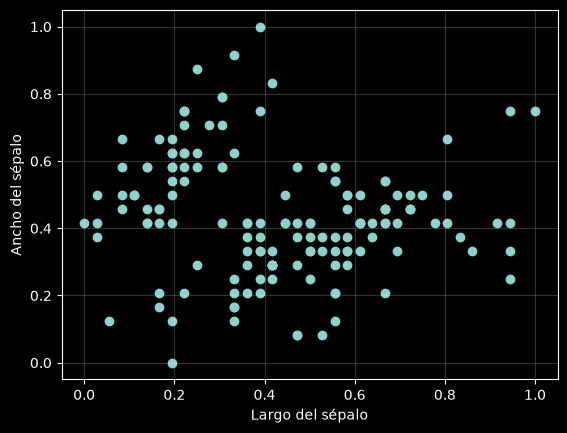

In [ ]:
# 4. Graficamente
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
)
plt.xlabel("Largo del sépalo")
plt.ylabel("Ancho del sépalo")
plt.grid(alpha = 0.2)

-----

### 5. entrenar el modelo

In [ ]:
model = KMedians(
            n_clusters=K,
            random_state=42
        )

model.fit(X_scaled)
labels = model.labels_

---------

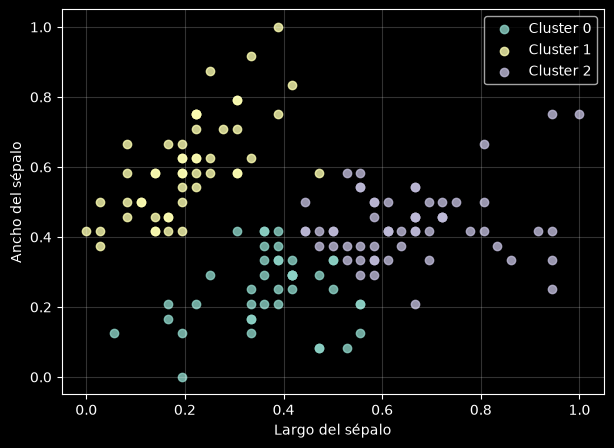

In [ ]:
plt.figure(figsize=(7, 5))
for cluster in range(K):
    mask = labels == cluster
    plt.scatter(
        X_scaled[mask, 0], X_scaled[mask, 1],
        alpha=0.8, label=f"Cluster {cluster}"
    )
    plt.scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        marker="P", s=220, c="white", edgecolors="black"
    )

plt.legend()
plt.xlabel("Largo del sépalo")
plt.ylabel("Ancho del sépalo")
plt.grid(alpha = 0.2)

-------

### 6. Mostrar centros en las unidades originales


In [101]:
centros_originales = scaler.inverse_transform(model.cluster_centers_)
tabla_centros = pd.DataFrame(centros_originales, columns=columnas)
tabla_centros.index.name = "cluster"

print("Centros de K-Medians (valores originales):")
print(tabla_centros)

print(f"\nInercia Manhattan: {model.inertia_:.4f}")

Centros de K-Medians (valores originales):
         sepal length (cm)  sepal width (cm)
cluster                                     
0                      5.7               2.6
1                      5.0               3.4
2                      6.6               3.0

Inercia Manhattan: 26.9722


--------

### 7. Predecir clusters para datos nuevos


In [ ]:
nuevos = pd.DataFrame(
    [
        [5.1, 3.5],
        [6.7, 3.0],
        [5.8, 2.7],
    ],
    columns=columnas
)
nuevos

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,6.7,3.0
2,5.8,2.7


------

In [ ]:
# Importante: usar el scaler ya ajustado, sin volver a hacer fit
nuevos_scaled = scaler.transform(nuevos) # usar misma escala que los de entrenamiento
clusters_nuevos = model.predict(nuevos_scaled)

resultado = nuevos.copy()
resultado["cluster"] = clusters_nuevos

print(resultado)


   sepal length (cm)  sepal width (cm)  cluster
0                5.1               3.5        1
1                6.7               3.0        2
2                5.8               2.7        0


------

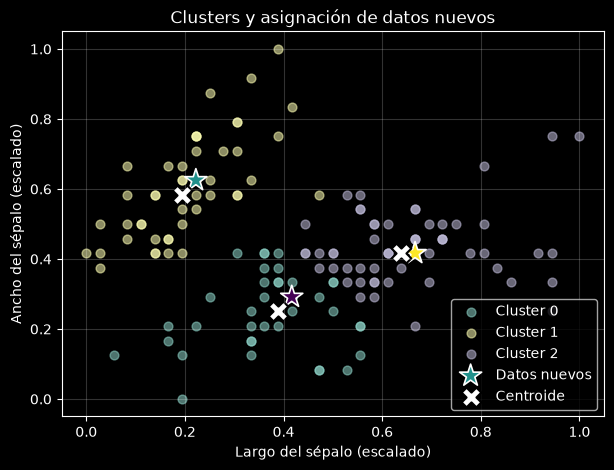

In [116]:
# 8. Graficar datos originales, centros y observaciones nuevas
plt.figure(figsize=(7, 5))

for cluster in range(K):
    mask = labels == cluster
    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        s=40,
        alpha=0.55,
        label=f"Cluster {cluster}"
    )

plt.scatter(
    nuevos_scaled[:, 0],
    nuevos_scaled[:, 1],
    c=clusters_nuevos,
    cmap="viridis",
    marker="*",
    s=280,
    edgecolors="white",
    linewidths=1.2,
    label="Datos nuevos"
)

plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    marker="X",
    s=200,
    c="white",
    edgecolors="black",
    linewidths=1.5,
    label="Centroide"
)

plt.xlabel("Largo del sépalo (escalado)")
plt.ylabel("Ancho del sépalo (escalado)")
plt.title("Clusters y asignación de datos nuevos")
plt.legend()
plt.grid(alpha=0.2)
plt.show()